In [3]:
from sklearn.impute import KNNImputer
import numpy as np
import pandas as pd

imputer = KNNImputer(n_neighbors=3)

df = pd.read_csv("outliers_imputation_practice.xls")

df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

df_imputed.isna().sum()

age                   0
experience_years      0
education_years       0
income                0
hours_per_week        0
performance_score     0
projects_completed    0
job_satisfaction      0
dtype: int64

In [4]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

imputer = IterativeImputer(max_iter=10, random_state=32)

df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

df_imputed.isna().sum()

age                   0
experience_years      0
education_years       0
income                0
hours_per_week        0
performance_score     0
projects_completed    0
job_satisfaction      0
dtype: int64

In [10]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")

df_mean = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

df_mean.isna().sum()

age                   0
experience_years      0
education_years       0
income                0
hours_per_week        0
performance_score     0
projects_completed    0
job_satisfaction      0
dtype: int64

In [11]:
from scipy.stats import zscore

data = np.array([10, 12, 11, 13, 12, 14, 100])

z_score = zscore(data)

outliers = data[np.abs(z_score) > 2]

print(outliers)

[100]


In [21]:
import numpy as np

df = pd.read_csv("outliers_imputation_practice.xls")

Q1 = df["income"].quantile(0.25)
Q3 = df["income"].quantile(0.75)

IQR = Q3 - Q1

lower_bond = Q1 - 1.5 * IQR
upper_bond = Q3 + 1.5 * IQR

outliers = df[(df["income"] >= lower_bond) & (df["income"] <= upper_bond)]

display(outliers)

outliers.count()

,age,experience_years,education_years,income,hours_per_week,performance_score,projects_completed,job_satisfaction
0,56.0,34.0,16.0,192108.58,33.0,100.00,29.0,7.10
1,46.0,19.0,12.0,115700.97,32.2,93.18,17.0,NaN
2,32.0,14.0,16.0,118094.75,37.9,89.85,13.0,7.52
3,60.0,37.0,14.0,207761.74,49.3,100.00,NaN,5.51
4,25.0,NaN,16.0,53154.85,31.4,NaN,0.0,10.00
...,...,...,...,...,...,...,...,...
995,50.0,31.0,16.0,170826.96,37.6,100.00,24.0,8.83
996,21.0,0.0,12.0,50426.91,38.6,59.19,4.0,8.82
997,39.0,NaN,12.0,120388.75,46.4,89.10,16.0,8.97
998,19.0,0.0,14.0,42263.64,42.2,90.18,2.0,7.24


age                   866
experience_years      849
education_years       861
income                894
hours_per_week        841
performance_score     822
projects_completed    831
job_satisfaction      813
dtype: int64

In [22]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

display(df_scaled)

,age,experience_years,education_years,income,hours_per_week,performance_score,projects_completed,job_satisfaction
0,0.904762,0.850,0.75,0.202808,0.130008,1.000000,0.180124,0.601100
1,0.666667,0.475,0.25,0.114234,0.120964,0.922613,0.105590,NaN
2,0.333333,0.350,0.75,0.117009,0.185403,0.884827,0.080745,0.658872
3,1.000000,0.925,0.50,0.220954,0.314280,1.000000,NaN,0.382393
4,0.166667,NaN,0.75,0.041729,0.111920,NaN,0.000000,1.000000
...,...,...,...,...,...,...,...,...
995,0.761905,0.775,0.75,0.178138,0.182011,1.000000,0.149068,0.839065
996,0.071429,0.000,0.25,0.038566,0.193316,0.536925,0.024845,0.837689
997,0.500000,NaN,0.25,0.119668,0.281496,0.876317,0.099379,0.858322
998,0.023810,0.000,0.50,0.029103,0.234014,0.888572,0.012422,0.620358


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns
)

display(df_scaled)

,age,experience_years,education_years,income,hours_per_week,performance_score,projects_completed,job_satisfaction
0,1.367945,1.436700,0.673173,0.993906,-1.075163,0.882582,1.202142,0.219877
1,0.558362,0.178683,-1.258804,-0.113911,-1.168017,0.409342,0.099042,NaN
2,-0.575054,-0.240657,0.673173,-0.079204,-0.506435,0.178272,-0.268658,0.496697
3,1.691778,1.688304,-0.292815,1.220858,0.816729,0.882582,NaN,-0.828085
4,-1.141762,NaN,0.673173,-1.020754,-1.260870,NaN,-1.463684,2.131254
...,...,...,...,...,...,...,...,...
995,0.882195,1.185097,0.673173,0.685348,-0.541255,0.882582,0.742517,1.360112
996,-1.465595,-1.414806,-1.258804,-1.060306,-0.425188,-1.949229,-1.095984,1.353522
997,-0.008346,NaN,-1.258804,-0.045944,0.480135,0.126230,0.007117,1.452386
998,-1.627512,-1.414806,-0.292815,-1.178663,-0.007346,0.201171,-1.279834,0.312151


In [24]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns
)

display(df_scaled)

,age,experience_years,education_years,income,hours_per_week,performance_score,projects_completed,job_satisfaction
0,0.727273,0.809524,0.0,0.745157,-0.919192,0.381437,0.8125,0.163823
1,0.272727,0.095238,-2.0,-0.065218,-1.000000,0.063417,0.0625,NaN
2,-0.363636,-0.142857,0.0,-0.039830,-0.424242,-0.091862,-0.1875,0.354949
3,0.909091,0.952381,-1.0,0.911174,0.727273,0.381437,NaN,-0.559727
4,-0.681818,NaN,0.0,-0.728580,-1.080808,NaN,-1.0000,1.483504
...,...,...,...,...,...,...,...,...
995,0.454545,0.666667,0.0,0.519445,-0.454545,0.381437,0.5000,0.951081
996,-0.863636,-0.809524,-2.0,-0.757512,-0.353535,-1.521550,-0.7500,0.946530
997,-0.045455,NaN,-2.0,-0.015500,0.434343,-0.126835,0.0000,1.014790
998,-0.954545,-0.809524,-1.0,-0.844091,0.010101,-0.076474,-0.8750,0.227531


In [29]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=3)

poly = PolynomialFeatures(degree=2, include_bias=False)

x = df[["income"]]

df_imputed = pd.DataFrame(
    imputer.fit_transform(x),
    columns=["income"]
)

df_poly = pd.DataFrame(
    poly.fit_transform(df_imputed),
    columns=["income", "income ^ 3"]
)

display(df_poly)

,income,income ^ 3
0,192108.58,3.690571e+10
1,115700.97,1.338671e+10
2,118094.75,1.394637e+10
3,207761.74,4.316494e+10
4,53154.85,2.825438e+09
...,...,...
995,170826.96,2.918185e+10
996,50426.91,2.542873e+09
997,120388.75,1.449345e+10
998,42263.64,1.786215e+09


In [37]:
df = pd.read_csv("ecommerce_orders_messy.csv")

df_enocded = pd.get_dummies(
    df,
    columns=["city"],
    dtype=int
)

display(df_enocded)

,order_id,customer_id,age,gender,annual_income,signup_date,order_date,product_category,quantity,unit_price,...,city_PUNE,city_Pune,city_bengaluru,city_chennai,city_delhi,city_hyderabad,city_kochi,city_kozhikode,city_mumbai,city_pune
0,ORD10546,C1085,37.0,Male,89332.0,2022-12-16,2023-10-30,Clothing,4,2622.92,...,0,0,0,0,0,0,0,0,0,0
1,ORD10980,C1451,40.0,Female,60363.0,2022-09-25,2023-03-03,Groceries,3,451.64,...,0,0,0,0,0,0,0,0,0,0
2,ORD10908,C1388,36.0,Male,68146.0,2024-08-03,2025-06-21,Sports,2,2532.15,...,0,0,0,0,0,0,0,0,0,0
3,ORD10577,C1143,49.0,Female,95283.0,2022-02-21,2022-10-06,Electronics,5,8198.78,...,0,0,0,0,0,0,0,0,0,0
4,ORD10846,C1490,70.0,Female,105040.0,2024-06-18,2025-05-18,Electronics,2,8258.96,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,ORD10299,C1497,39.0,Female,60116.0,2024-03-29,2025-03-05,Home & Kitchen,2,955.03,...,0,1,0,0,0,0,0,0,0,0
1021,ORD10534,C1244,18.0,Female,43838.0,2024-06-30,2024-11-16,Clothing,4,2859.18,...,0,0,0,0,0,0,0,0,0,0
1022,ORD10584,C1150,43.0,Male,64894.0,2023-10-05,2024-03-21,Electronics,2,5945.20,...,0,0,0,0,0,0,0,0,0,0
1023,ORD10493,C1239,40.0,Female,79282.0,2022-09-07,2023-07-02,Clothing,1,1865.30,...,0,0,0,0,0,0,0,0,0,0


In [39]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Gender"] = encoder.fit_transform(df["gender"])

display(df)

,order_id,customer_id,age,gender,city,annual_income,signup_date,order_date,product_category,quantity,unit_price,discount_pct,total_amount,payment_method,customer_rating,returned,Gender
0,ORD10546,C1085,37.0,Male,Bengaluru,89332.0,2022-12-16,2023-10-30,Clothing,4,2622.92,0,10491.70,UPI,4.0,0,4
1,ORD10980,C1451,40.0,Female,Chennai,60363.0,2022-09-25,2023-03-03,Groceries,3,451.64,0,1354.93,Cash on Delivery,3.0,0,1
2,ORD10908,C1388,36.0,Male,Kozhikode,68146.0,2024-08-03,2025-06-21,Sports,2,2532.15,10,4557.87,UPI,3.0,0,4
3,ORD10577,C1143,49.0,Female,Delhi,95283.0,2022-02-21,2022-10-06,Electronics,5,8198.78,0,40993.91,Debit Card,1.0,0,1
4,ORD10846,C1490,70.0,Female,Mumbai,105040.0,2024-06-18,2025-05-18,Electronics,2,8258.96,0,16517.93,Net Banking,1.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,ORD10299,C1497,39.0,Female,Pune,60116.0,2024-03-29,2025-03-05,Home & Kitchen,2,955.03,0,1910.06,Credit Card,2.0,0,1
1021,ORD10534,C1244,18.0,Female,Chennai,43838.0,2024-06-30,2024-11-16,Clothing,4,2859.18,25,8577.53,Credit Card,2.0,1,1
1022,ORD10584,C1150,43.0,Male,Kochi,64894.0,2023-10-05,2024-03-21,Electronics,2,5945.20,25,8917.81,Cash on Delivery,2.0,0,4
1023,ORD10493,C1239,40.0,Female,Kozhikode,79282.0,2022-09-07,2023-07-02,Clothing,1,1865.30,0,1865.30,Cash on Delivery,3.0,0,1


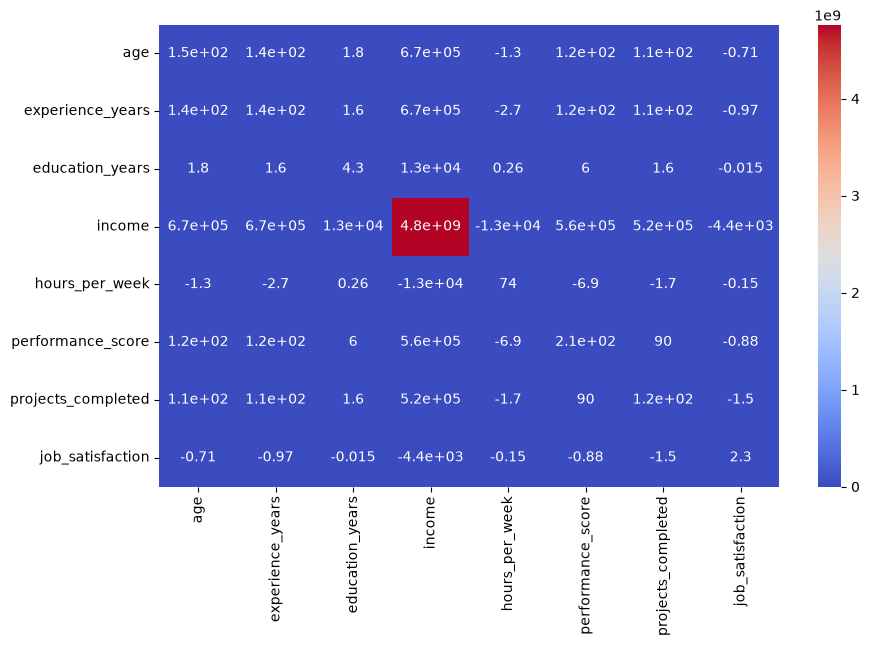

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("outliers_imputation_practice.xls")

plt.figure(figsize=(10, 6))

df_corr = df.cov(numeric_only=True)

sns.heatmap(df_corr, annot=True, cmap="coolwarm")

plt.show()

In [44]:
import pandas as pd

df = pd.read_csv("outliers_imputation_practice.xls")

correlation = (df.corr(numeric_only=True)["age"].sort_values(ascending=False))

print(correlation)

age                   1.000000
experience_years      0.971990
projects_completed    0.844886
income                0.777266
performance_score     0.680879
education_years       0.070049
hours_per_week       -0.012017
job_satisfaction     -0.037613
Name: age, dtype: float64


In [46]:
from sklearn.feature_selection import VarianceThreshold
import pandas as pd

df = pd.read_csv("outliers_imputation_practice.xls")

selector = VarianceThreshold()

df_selected = pd.DataFrame(
    selector.fit_transform(df),
    columns=df.columns[selector.get_support()]
)

display(df_selected)

,age,experience_years,education_years,income,hours_per_week,performance_score,projects_completed,job_satisfaction
0,56.0,34.0,16.0,192108.58,33.0,100.00,29.0,7.10
1,46.0,19.0,12.0,115700.97,32.2,93.18,17.0,NaN
2,32.0,14.0,16.0,118094.75,37.9,89.85,13.0,7.52
3,60.0,37.0,14.0,207761.74,49.3,100.00,NaN,5.51
4,25.0,NaN,16.0,53154.85,31.4,NaN,0.0,10.00
...,...,...,...,...,...,...,...,...
995,50.0,31.0,16.0,170826.96,37.6,100.00,24.0,8.83
996,21.0,0.0,12.0,50426.91,38.6,59.19,4.0,8.82
997,39.0,NaN,12.0,120388.75,46.4,89.10,16.0,8.97
998,19.0,0.0,14.0,42263.64,42.2,90.18,2.0,7.24


In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE

model = LinearRegression()

rfe = RFE(estimator=model, n_features_to_select=3)

X = df.drop(columns=["age"])
y = df["age"]

X = X.fillna(X.median())
y = y.fillna(y.median())

rfe.fit(X, y)

selected_features = X.columns[rfe.get_support()]

display(selected_features)

Index(['experience_years', 'projects_completed', 'job_satisfaction'], dtype='str')

In [ ]:
from sklearn.linear_model import Lasso

X = df.drop(columns=["income"])
y = df["income"]

X = X.fillna(X.median())
y = y.fillna(y.median())

lasso = Lasso(alpha=0.1)

lasso.fit(X, y)

coeff = pd.DataFrame({
    "Feature": X.columns,
    "coeff": lasso.coef_
})

display(coeff)

,Feature,coeff
0,age,1130.951618
1,experience_years,2824.800371
2,education_years,1089.222335
3,hours_per_week,-35.357355
4,performance_score,114.929902
5,projects_completed,256.671345
6,job_satisfaction,-37.248564


In [65]:
from sklearn.linear_model import Ridge

X = df.drop(columns=["income"])
y = df["income"]

X = X.fillna(X.median())
y = y.fillna(y.median())

ridge = Ridge(alpha=0.1)

ridge.fit(X, y)

coeff = pd.DataFrame({
    "Feature" : X.columns,
    "Coeff" : ridge.coef_
})

display(coeff)

,Feature,Coeff
0,age,1130.880678
1,experience_years,2824.851457
2,education_years,1089.436157
3,hours_per_week,-35.371807
4,performance_score,114.930210
5,projects_completed,256.691608
6,job_satisfaction,-37.713513


9
